<a href="https://colab.research.google.com/github/hugo12341234/machine-learning-projects/blob/main/01-car-price-prediction/car_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Car Price Prediction
**Author:** Hugo Chacón
**Course:** SIAFI

# Summary
In this project, I develop a Machine Learning model to predict the selling price of used cars based on historical data from Car Dekho. I follow the complete Data Science pipeline: Cleaning, Exploratory Data Analysis (EDA), Feature Engineering, and Model Optimization.


# PROJECT WORKFLOW & LOGIC

'''
1. Problem Definition
   Objective: I need to predict the exact selling price of used cars based on their specs.
   ML Problem: Since "Price" is a continuous number (not a Yes/No label), this is a Regression task.
   Success Criteria: I'll consider it a success if I get an R2 Score above 0.70 and if the average error (MAE) is reasonable for the market.

2. Data Collection and Preparation
   Acquisition: Loading the 'Car Dekho' dataset.
   Cleaning: I'm removing duplicates to prevent the model from cheating (memorizing), and filtering out 'Test Drive Cars' because they are extreme outliers that distort the trend.
   EDA: Before modeling, I use histograms and scatterplots to understand how price behaves and how it drops as cars get older.

3. Feature Engineering and Selection
   Engineering: Raw data wasn't enough, so I got creative:
     - Calculated 'Age' from the year (older = cheaper).
     - Applied Log Transformation to price to fix the massive gap between a Maruti (50k) and a BMW (5M).
     - Grouped rare brands into 'Other' so the model focuses on the big players.
   Selection: I dropped text columns like 'Name' that don't add value mathematically.
   Encoding: Converted text labels (Fuel, Transmission) into numbers (0s and 1s) so the algorithm can process them.

4. Model Selection, Training, and Tuning
   Selection: I tried Linear Regression (too simple) and SVM (too rigid). I chose 'Gradient Boosting Regressor' because it's the best at understanding non-linear patterns, like how a car loses 30% value just by driving off the lot.
   Tuning: I configured it with 500 trees and a max depth of 4. This is the "sweet spot" I found—complex enough to learn, but simple enough to avoid overfitting.

5. Model Evaluation and Interpretation
   Evaluation: I'm verifying the performance using R2 Score (Precision) and RMSE (Average error).
   Validation: I'm also checking the "Residuals" (errors). If they are random, the model is healthy. If they follow a pattern, the model is biased.        '''

In [ ]:
# IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ==========================================
# STEP 2. Data Collection and Preparation
# ==========================================

In [ ]:
# 2.1 Data Acquisition
# Load the dataset
df = pd.read_csv('CAR DETAILS FROM CAR DEKHO.csv')

# Drop duplicates
# I decided to drop these duplicates because if the model sees the same car data multiple times, it might overfit (basically memorizing those specific cars instead of learning the pattern).
df = df.drop_duplicates()

# Filter out 'Test Drive Car'
# I'm removing these because 'Test Drive Cars' are basically new cars with weird pricing and very low mileage. They are outliers that would just confuse the regression model.
df = df[df['owner'] != 'Test Drive Car']

print(f"Dimensions after removing duplicates: {df.shape}")
print(df.head())
print(df.info())

Dimensions after removing duplicates: (3560, 8)
                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  
<class 'pandas.core.frame.DataFrame'>
Index: 3560 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           3560 non-null   object
 1   year           3560 non-null   i

# ==========================================
# Exploratory Data Analysis (EDA)
# ==========================================

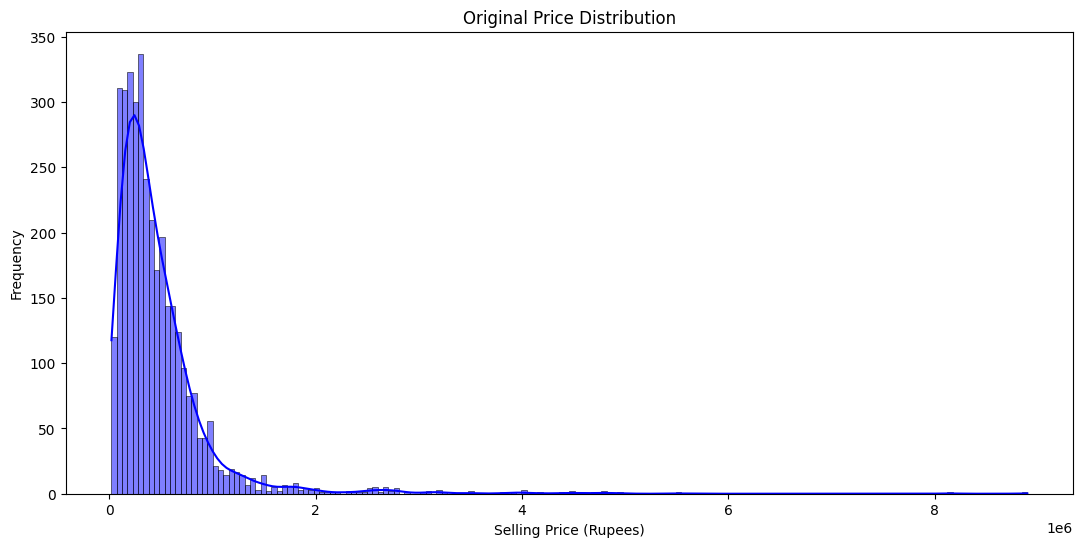

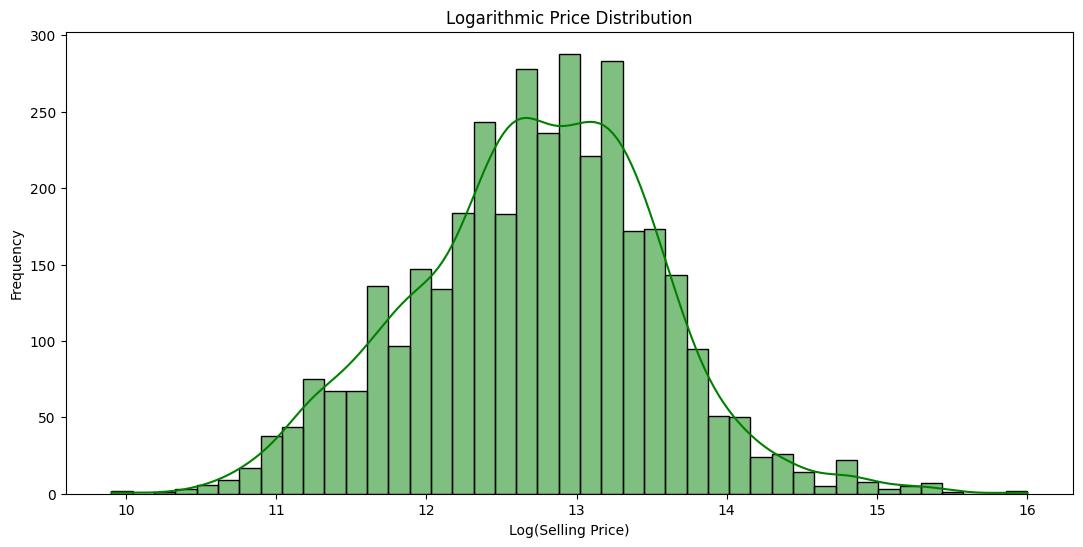

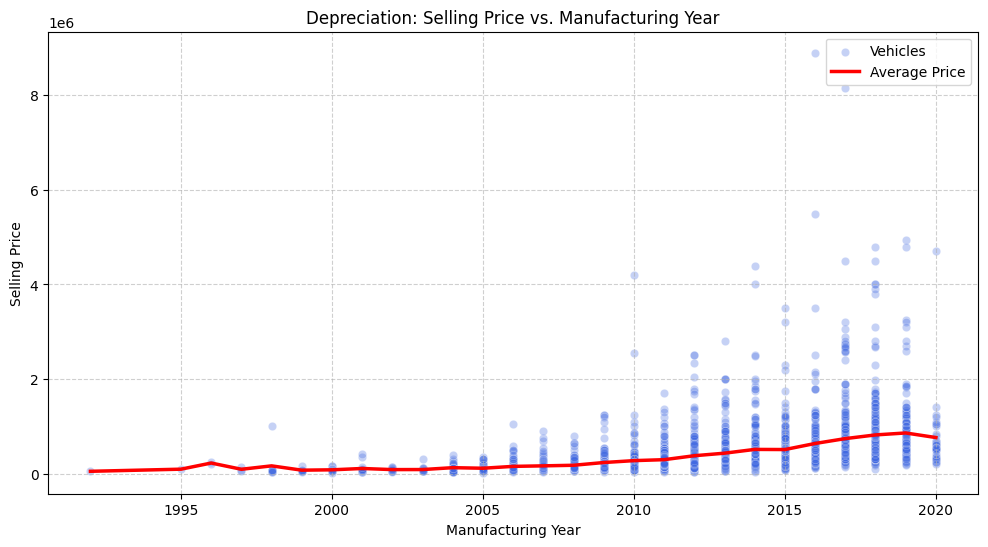

/tmp/ipython-input-1070765416.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[coord], data=df, x=col, y='selling_price', order=order, palette='viridis')
/tmp/ipython-input-1070765416.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[coord], data=df, x=col, y='selling_price', order=order, palette='viridis')
/tmp/ipython-input-1070765416.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[coord], data=df, x=col, y='selling_price', order=order, palette='viridis')
/tmp/ipython-input-1070765416.py:53: FutureWarnin

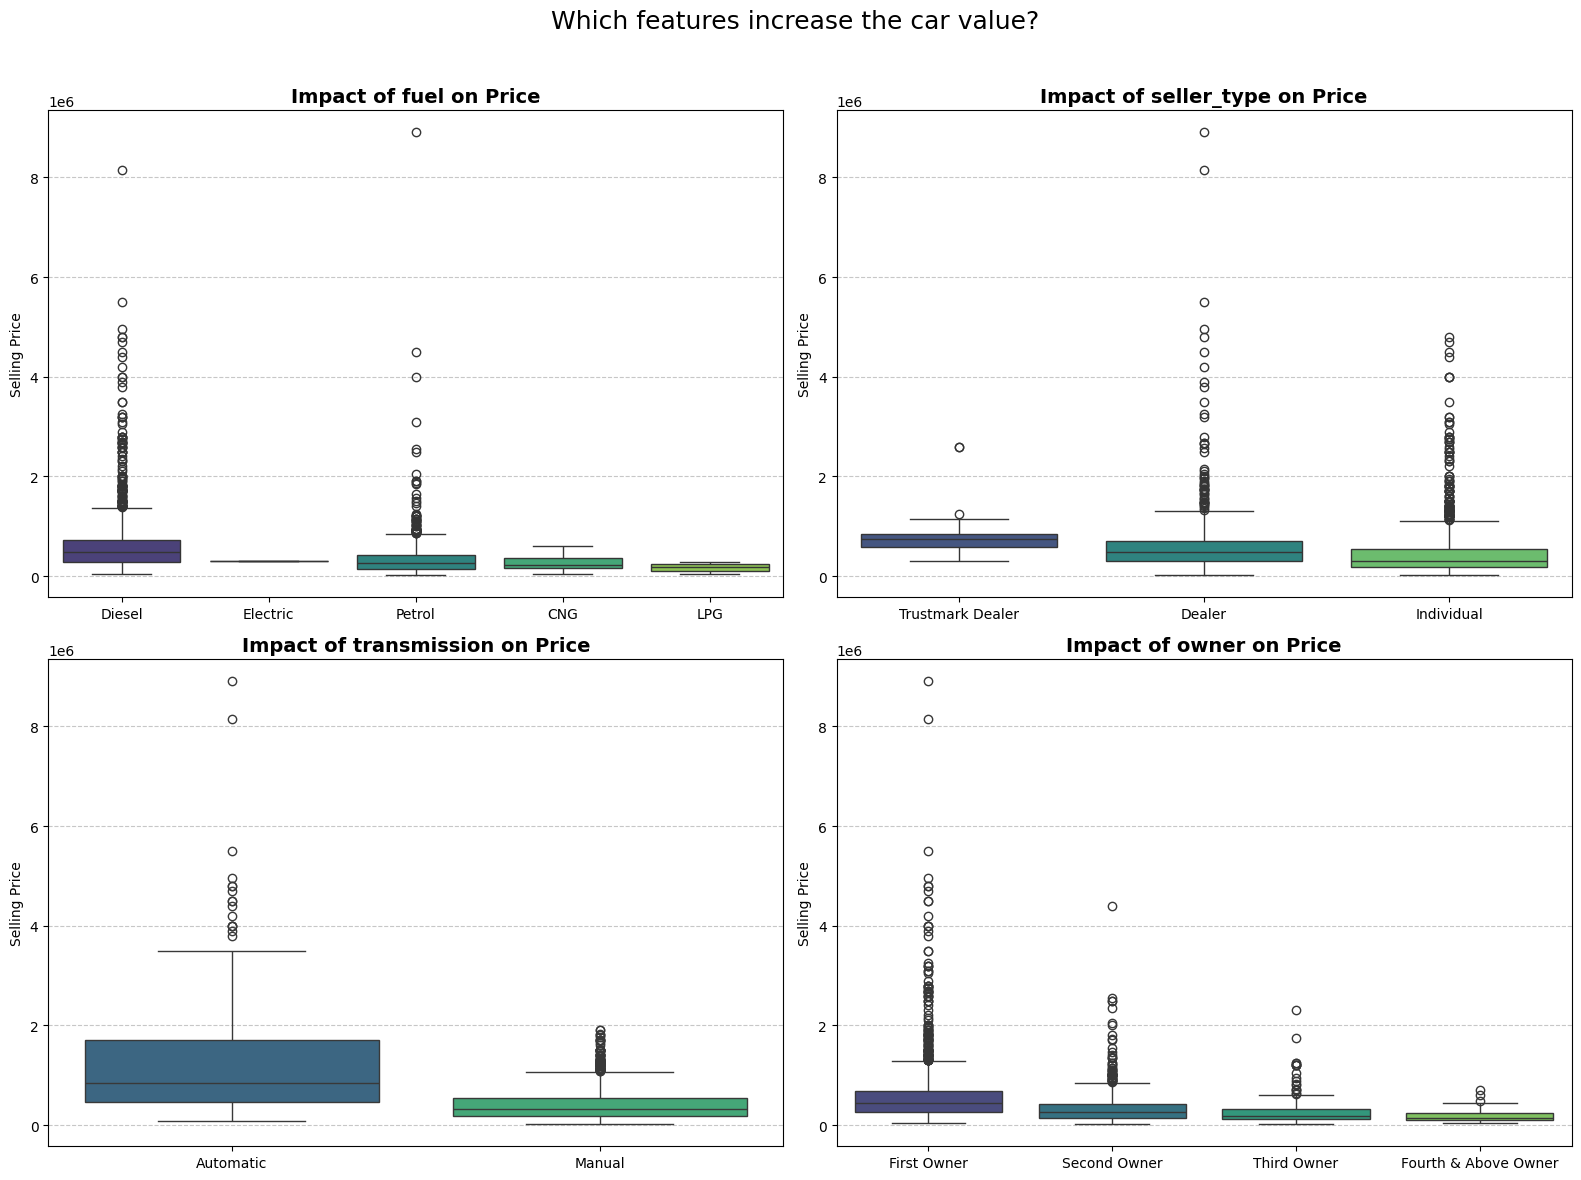

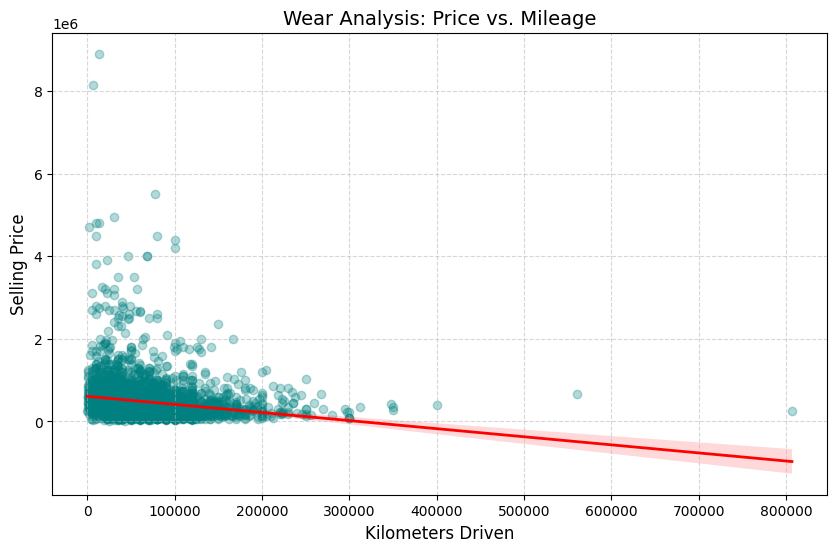

/tmp/ipython-input-1070765416.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=brand_avg_price, x='brand', y='selling_price', palette='viridis')


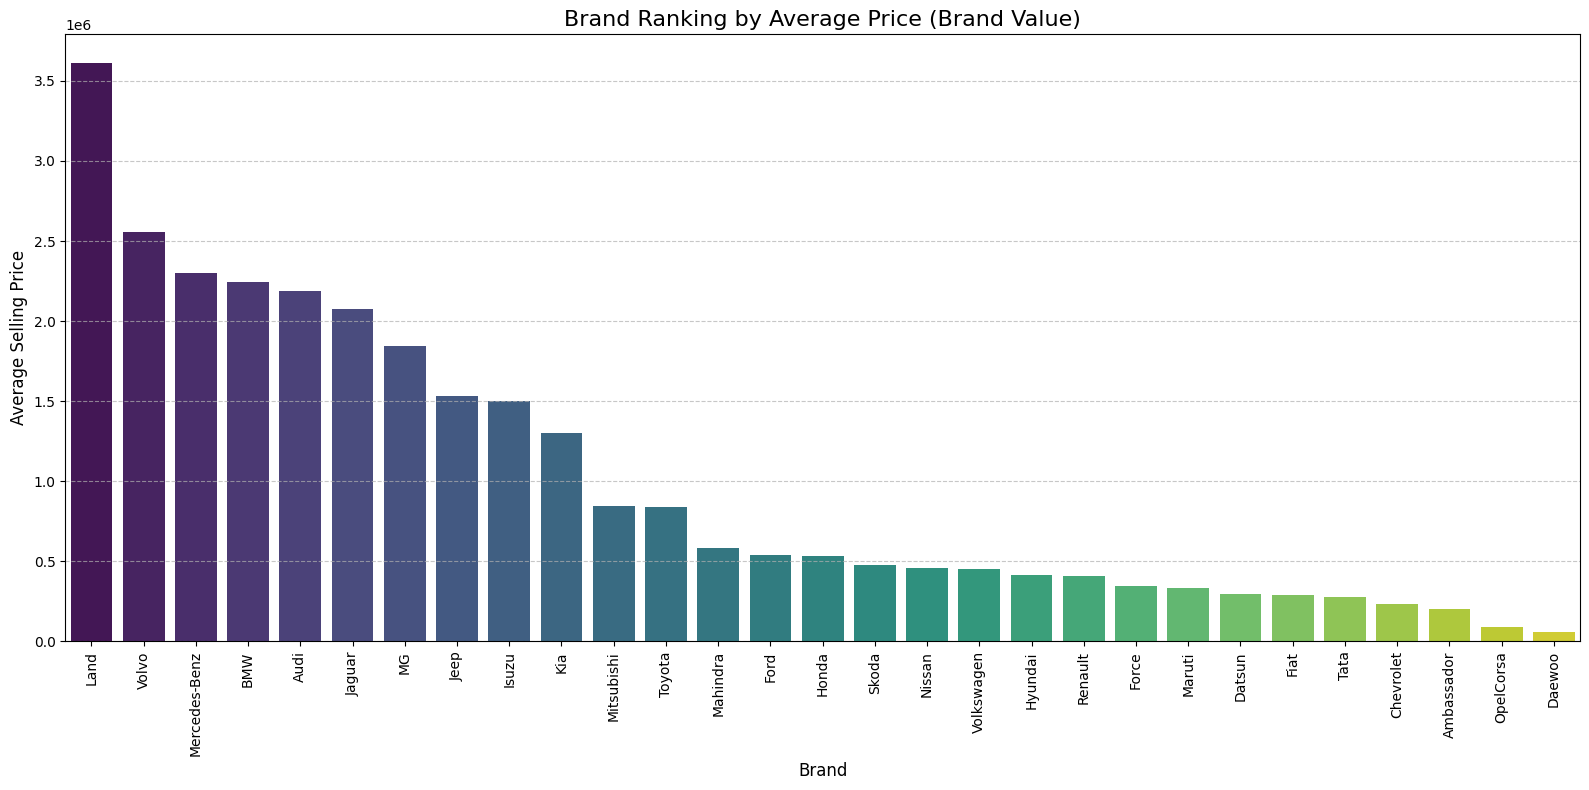

/tmp/ipython-input-1070765416.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[i], data=df, x=var, palette='viridis', order=df[var].value_counts().index)
/tmp/ipython-input-1070765416.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[i], data=df, x=var, palette='viridis', order=df[var].value_counts().index)
/tmp/ipython-input-1070765416.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[i], data=df, x=var, palette='viridis', order=df[var].value_counts().index)
/tmp/ipython-input-1070765416.py:107: Fu

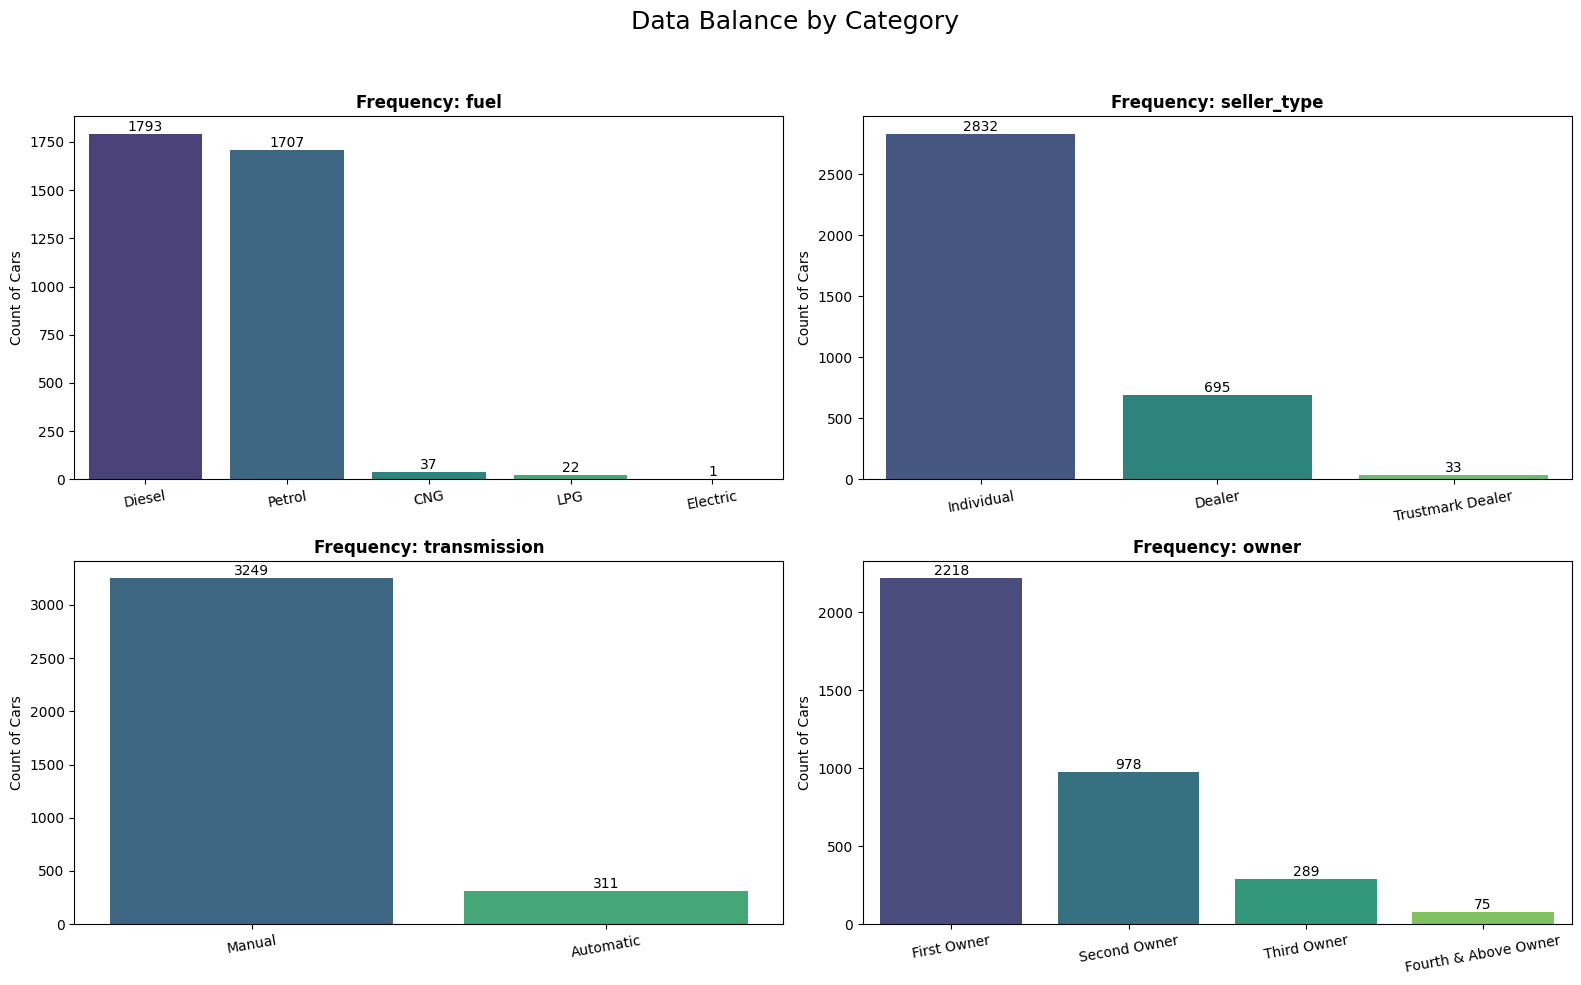

/tmp/ipython-input-1070765416.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='brand', order=top_brands, palette='magma')


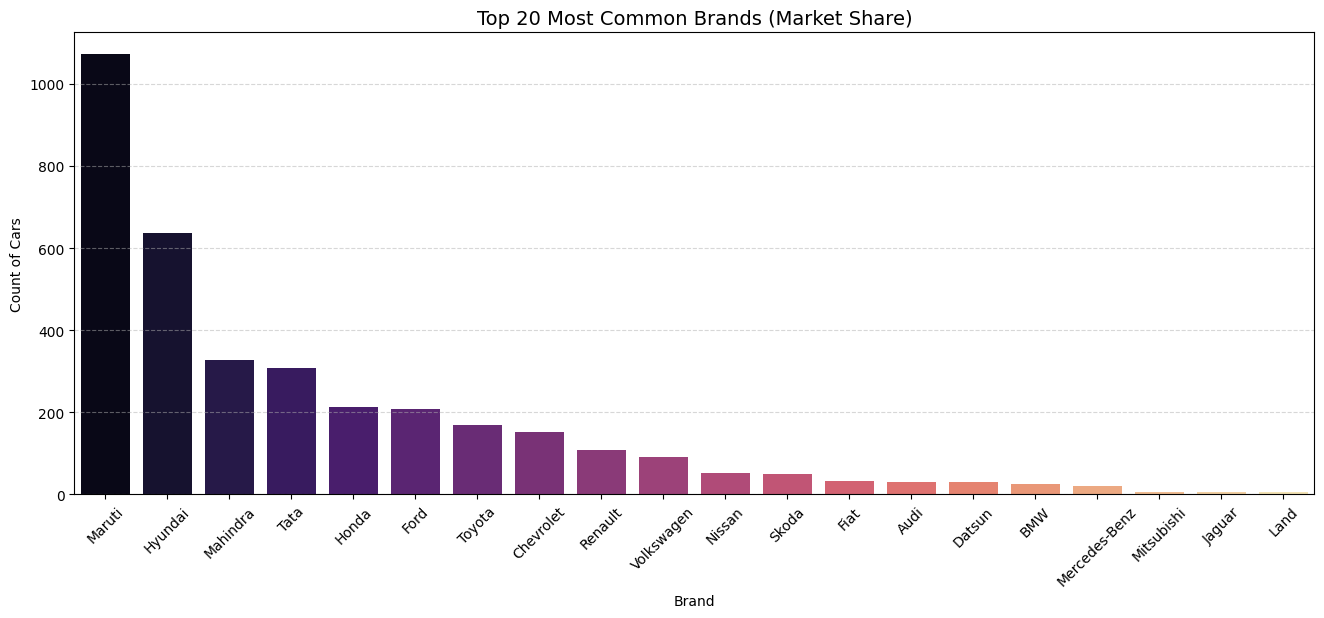

In [ ]:
# Histogram (selling_price)
# I decide to use a histogram because I want to see the distribution of the prices (what is the most common price).
plt.figure(figsize=(13, 6))
sns.histplot(df['selling_price'], kde=True, color='blue')
plt.title('Original Price Distribution')
plt.xlabel('Selling Price (Rupees)')
plt.ylabel('Frequency')
plt.show()
# The result shows a right-skewed distribution, which means that most of the prices are lower than the mean (many cheap cars, few expensive ones).
# This non-normality can negatively affect the model when it tries to make predictions about the price of a car.
# I will apply a log transformation to fix this. Basically, the gap between 1 million and 2 million is huge, but in log scale it's smaller, which helps the model handle the data better.

# Log Transformed Histogram
plt.figure(figsize=(13, 6))
sns.histplot(np.log1p(df['selling_price']), kde=True, color='green')
plt.title('Logarithmic Price Distribution')
plt.xlabel('Log(Selling Price)')
plt.ylabel('Frequency')
plt.show()
# Now the distribution is more normal (bell-shaped).
# Y-axis (10-16): The axis shows the Natural Logarithm of the price (ln(price)). 10 corresponds to e^10 (~22,000) - 16 corresponds to e^16 (~8,900,000).


# Depreciation (Year vs Price)
plt.figure(figsize=(12, 6))
# Use a Scatterplot to show the relationship between the year and the selling price.
sns.scatterplot(data=df, x='year', y='selling_price', alpha=0.3, color='royalblue', label='Vehicles')

avg_price = df.groupby('year')['selling_price'].mean().reset_index()
# Use a Line Chart to show the trend of the price per year.
# I added this line plot on top because just looking at the dots makes it hard to see the average depreciation trend clearly.
sns.lineplot(data=avg_price, x='year', y='selling_price', color='red', linewidth=2.5, label='Average Price')

plt.title('Depreciation: Selling Price vs. Manufacturing Year')
plt.xlabel('Manufacturing Year')
plt.ylabel('Selling Price')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()


# Categorical Variables Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Which features increase the car value?', fontsize=18)

categorical_vars = ['fuel', 'seller_type', 'transmission', 'owner']
coords = [(0, 0), (0, 1), (1, 0), (1, 1)]

for col, coord in zip(categorical_vars, coords):
    order = df.groupby(col)['selling_price'].median().sort_values(ascending=False).index
    # Use boxplot to show the relationship between a categorical variable and price.
    # I chose boxplots here instead of bar charts because outliers were messing up the averages. The median (line in the middle of the box) gives a more honest representation of the 'typical' price.
    sns.boxplot(ax=axes[coord], data=df, x=col, y='selling_price', order=order, palette='viridis')
    axes[coord].set_title(f'Impact of {col} on Price', fontsize=14, fontweight='bold')
    axes[coord].set_xlabel('')
    axes[coord].set_ylabel('Selling Price')
    axes[coord].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# Wear Analysis (Km vs Price)
plt.figure(figsize=(10, 6))
# I use regplot instead of simple scatterplot.
# I switched to regplot because it automatically draws that red trend line, which makes it super obvious if the price really drops as kilometers go up.
sns.regplot(data=df, x='km_driven', y='selling_price',
            scatter_kws={'alpha': 0.3, 'color': 'teal'},
            line_kws={'color': 'red', 'linewidth': 2})

plt.title('Wear Analysis: Price vs. Mileage', fontsize=14)
plt.xlabel('Kilometers Driven', fontsize=12)
plt.ylabel('Selling Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


# Brand Extraction & Analysis
# First I Extract the Brand
# I assume the 'name' column has the format "Make Model ..." (e.g. "Maruti Swift Dzire").
# I take the first word as the brand.
df['brand'] = df['name'].str.split().str[0]

# 1. Group by brand and calculate average price
brand_avg_price = df.groupby('brand')['selling_price'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(16, 8))
# 2. Barplot (Bar Chart)       I want to see how much the brand affects the price.
sns.barplot(data=brand_avg_price, x='brand', y='selling_price', palette='viridis')
plt.title('Brand Ranking by Average Price (Brand Value)', fontsize=16)
plt.xlabel('Brand', fontsize=12)
plt.ylabel('Average Selling Price', fontsize=12)
plt.xticks(rotation=90, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# Data Balance Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Data Balance by Category', fontsize=18)
axes = axes.flatten()

for i, var in enumerate(categorical_vars):
    # Countplot: Counts how many rows there are of each type
    # order: I sort from highest to lowest frequency to look clean
    sns.countplot(ax=axes[i], data=df, x=var, palette='viridis', order=df[var].value_counts().index)

    axes[i].set_title(f'Frequency: {var}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Count of Cars')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=10)
    for container in axes[i].containers:
        axes[i].bar_label(container)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Brand Distribution
plt.figure(figsize=(16, 6))
# I only show the Top 20 so as not to saturate the graph.
# If I showed all of them, the x-axis would be a mess of unreadable text.
top_brands = df['brand'].value_counts().head(20).index
sns.countplot(data=df, x='brand', order=top_brands, palette='magma')
plt.title('Top 20 Most Common Brands (Market Share)', fontsize=14)
plt.xlabel('Brand')
plt.ylabel('Count of Cars')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


 GENERAL ANALYSIS

1. (selling_price)
The massive chunk of data is piled up on the left side (low prices, < 500k), also I see a thin line stretching way out to the right, reaching super high values (almost 9 million).
so the market is dominated by cheaps cars. Luxury cars are rare cases (outliers) that break the normal pattern, but I tried to fix this by applying a log transformation.

2. (Scatterplots)
Price vs Age
I see a drop. Points start high on the Y-axis when age is low (0-5 years) and fall as you move to the right.

- (0-5 years): average ~700k.
- (5-10 years): average (~400k).
- (15+ years): average (~100k).

So a car loses more than half of his value in the first 10 years.

Price vs. Km Driven
It's a more scattered cloud than the age one.
I see cars with 100,000 km that are worth a lot and others worth very little. that means that mileage alone doesn't dictate price as strongly as age does.

3. (Boxplots)
Price vs. Transmission
The "box" for Automatics is way higher than the one for Manuals.
The median line for automatics (850k) is almost three times higher than for manuals (320k). Also, the automatic box is longer, meaning their prices vary a lot more.

Price vs. Fuel

- Diesel: Median ~475k.
- Petrol: Median ~260k.
- CNG/LPG: Median < 230k.
Diesel commands a better value over petrol.

Price vs. Owner

The boxplots form a descending staircase.
- First Owner: Top step.
- Second Owner: Middle step.
- Third/Fourth: Low steps.
Every change of owner is a step down in price.

4. (Countplots)
Frequency Bar Charts

Fuel: I only see tall bars for Diesel and Petrol. The bars for CNG, LPG, and Electric are almost invisible.
Transmission: The "Manual" bar is giant compared to "Automatic". I have way more data on manual cars.

- Age is to important: The graph showing the clearest and nearest drop is Price vs. Age.
- Automatic and Diesel: The boxplots clearly separate these cars as the most expensive in the market.
- Unbalanced Data: The countplots warn me that I have very little info on electric or gas cars, so my predictions in those niches will be shaky.  '''

# =============================================================
# VARIABLE CORRECTION
# =============================================================

In [ ]:
# Creating the missing 'age' variable
# For the model, I need to convert year to age
if 'age' not in df.columns:
    current_year = df['year'].max()
    df['age'] = current_year - df['year']


# 3. Column Cleaning
#    I drop 'name' (I already extracted brand) and 'year' (I already have age)
cols_to_drop_now = ['name', 'year']
df = df.drop(columns=[c for c in cols_to_drop_now if c in df.columns])

# ============================================================
# STEP 3: FEATURE ENGINEERING AND SELECTION
# ============================================================

In [ ]:
# 1. ENGINEERING: Logarithmic Transformation (For price outliers)
df['log_selling_price'] = np.log1p(df['selling_price'])

# 2. ENGINEERING: New features are created from existing ones to help the model learn better

# A) Ordinal Encoding for 'owner' (Hierarchy: 1 > 2 > 3 > 4) the model can understand it now
owner_mapping = {
    'First Owner': 1,
    'Second Owner': 2,
    'Third Owner': 3,
    'Fourth & Above Owner': 4
}
df['owner_encoded'] = df['owner'].map(owner_mapping)

# B) Brand Grouping, the brands with less information are grouped together to reduce noise

top_brands = df['brand'].value_counts().nlargest(30).index
df['brand_grouped'] = df['brand'].apply(lambda x: x if x in top_brands else 'Other')

# C) One-Hot Encoding (For Fuel, Seller, Transmission)      now the model can understand it (1 for true, 0 for false).

df_processed = pd.get_dummies(df,
                              columns=['fuel', 'seller_type', 'transmission', 'brand_grouped'],
                              drop_first=True)            # drop_first=True to avoid multicollinearity

# 3. SELECTION: Dropping base columns
# I drop the original text columns and the price without log
cols_final_drop = ['selling_price', 'owner', 'brand']
df_processed = df_processed.drop(columns=[c for c in cols_final_drop if c in df_processed.columns])


# ==============================================================
# SPLIT & SCALE
# ==============================================================

In [ ]:
# 1. SPLIT: Define X (Predictors) and y (Target)
X = df_processed.drop(columns=['log_selling_price'])
y = df_processed['log_selling_price']

# Split: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# 2. SCALE: Standardization
# I only scale variables with large magnitudes (Age, Km, Owner)
cols_to_scale = ['age', 'km_driven', 'owner_encoded']

scaler = StandardScaler()

# The scaler learns only from X_train
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

# =================================================================
# DATA VALIDATION
# =================================================================



In [ ]:
# I join X_train (variables) with y_train (target) to see everything together
audit_df = X_train.copy()
audit_df['TARGET_log_price'] = y_train

# Saving the CSV file
file_name = 'data_ready_for_AI.csv'
audit_df.to_csv(file_name, index=False)

# ================================================================
# STEP 4 : (Balanced Gradient Boosting)
# ================================================================


  FINAL RESULT:
-> Accuracy (R2 Score): 0.7498
-> Average Error (MAE): 140,402


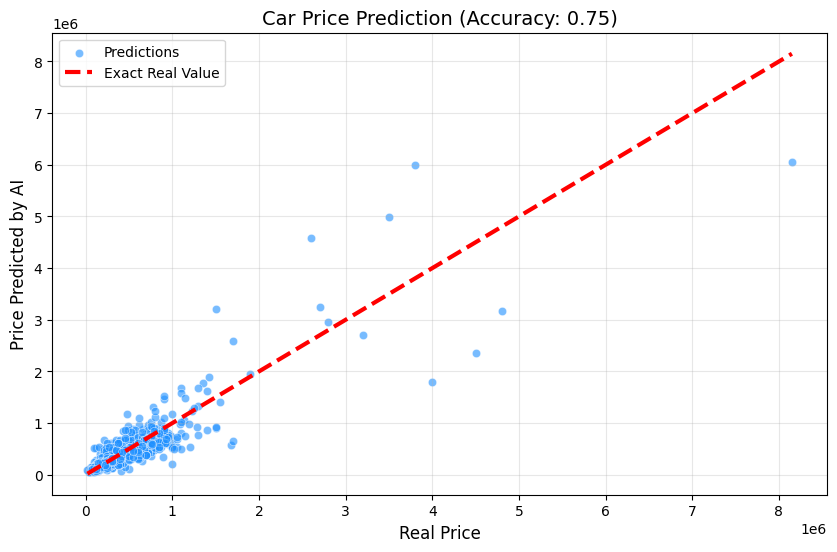

In [ ]:
# n_estimators=500: High enough to capture complex patterns, but stops before overfitting.
# learning_rate=0.15: A balanced speed. Too low would be slow; too high would miss the optimum.
# max_depth=4: I limited the depth to 4 so the trees don't memorize specific car details (noise).

final_model = GradientBoostingRegressor(n_estimators=500,
                                        learning_rate=0.15,
                                        max_depth=4,
                                        random_state=42)

final_model.fit(X_train, y_train)

# --- FINAL EVALUATION ---
y_pred_log = final_model.predict(X_test)
y_real = np.expm1(y_test)       # Real Price
y_pred = np.expm1(y_pred_log)   # Prediction

r2_final = r2_score(y_real, y_pred)
mae_final = mean_absolute_error(y_real, y_pred)

print(f"\n  FINAL RESULT:")
print(f"-> Accuracy (R2 Score): {r2_final:.4f}")
print(f"-> Average Error (MAE): {mae_final:,.0f}")

# --- GRAPH FOR YOUR ASSIGNMENT ---
plt.figure(figsize=(10, 6))
# Blue dots: Predictions
sns.scatterplot(x=y_real, y=y_pred, alpha=0.6, color='dodgerblue', label='Predictions')
# Red line: Perfection
plt.plot([y_real.min(), y_real.max()], [y_real.min(), y_real.max()], 'r--', lw=3, label='Exact Real Value')

plt.title(f'Car Price Prediction (Accuracy: {r2_final:.2f})', fontsize=14)
plt.xlabel('Real Price', fontsize=12)
plt.ylabel('Price Predicted by AI', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

'''
 (Step 4: Selection and Optimization)

#### Experiment 1:

Model: LinearRegression
Justification: Used as a baseline to establish initial performance.
Result: 0.59
The model showed underfitting. This confirmed to me that the relationship between age/km and price is not linear.

#### Experiment 2: Exploration with SVM

Model: SVR optimized with RandomizedSearchCV.
Configuration: Tested linear and rbf kernels, varying C and gamma regularization parameters.
Result: 0.64
Although slightly better than linear regression, SVM proved not to be the best for the mix of categorical (brands) and numerical data. Training was slow and accuracy gain was insignificant.

#### Experiment 3: (Data Correction + Gradient Boosting)

It was detected that the model had poor performance on high prices. Upon reviewing my data, I discovered that luxury brands (BMW, Audi, Mercedes) were being wrongly grouped into the "Others" category because they weren't in the Top 10 sales.
So:
1. Brand grouping was expanded from Top 10 to Top 30, allowing the model to distinguish premium vehicles.
2. I sought a model capable of handling complex data. Gradient Boosting was selected because it learns from its previous errors step-by-step, giving me better accuracy ($R^2 > 0.71$).

Result: jumped to 0.75.
Diagnosis: This was the biggest improvement. It confirmed that data quality (distinguishing luxury brands) was more important than the math complexity.

#### Experiment 4: Fine Tuning (Hyperparameter Tuning)

Model: GradientBoostingRegressor with Randomized Search (RandomizedSearchCV).
Attempt: Attempted to automatically optimize learning speed (learning_rate) and tree depth (max_depth) by testing 20 different combinations.
Result: oscillated between 0.67 and 0.71.

### Conclusion and Final Selection

After these 4 experiments, the model from Experiment 3 (Adjusted) was selected as the best one.

Final Model: Gradient Boosting Regressor.
Configuration: 500 trees, Depth 4, Learning rate 0.15.
Final Performance: of 0.75    '''

# ================================================================
# STEP 5: EVALUATION, INTERPRETATION AND VALIDATION
# ================================================================


  REPORT 
   -> MSE (Mean Squared Error): 75,944,419,706
   -> RMSE (Root Mean Squared Error): ₹ 275,580
   -> R2 Score (Explained Variance): 0.7498

 2. MODEL INTERPRETATION (What matters most?):


/tmp/ipython-input-2197826431.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=df_imp, palette='magma')


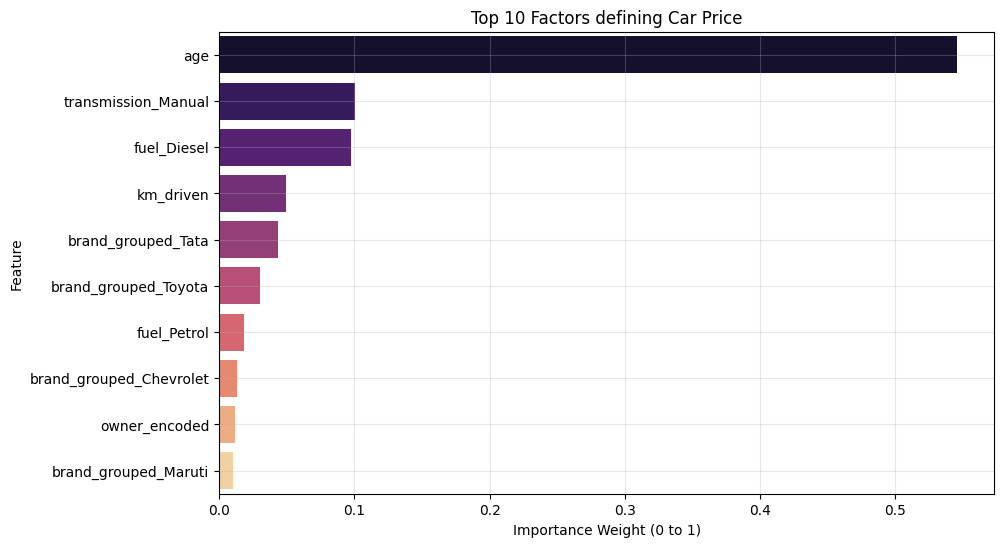


 3. CHECKING ERRORS (Residuals):


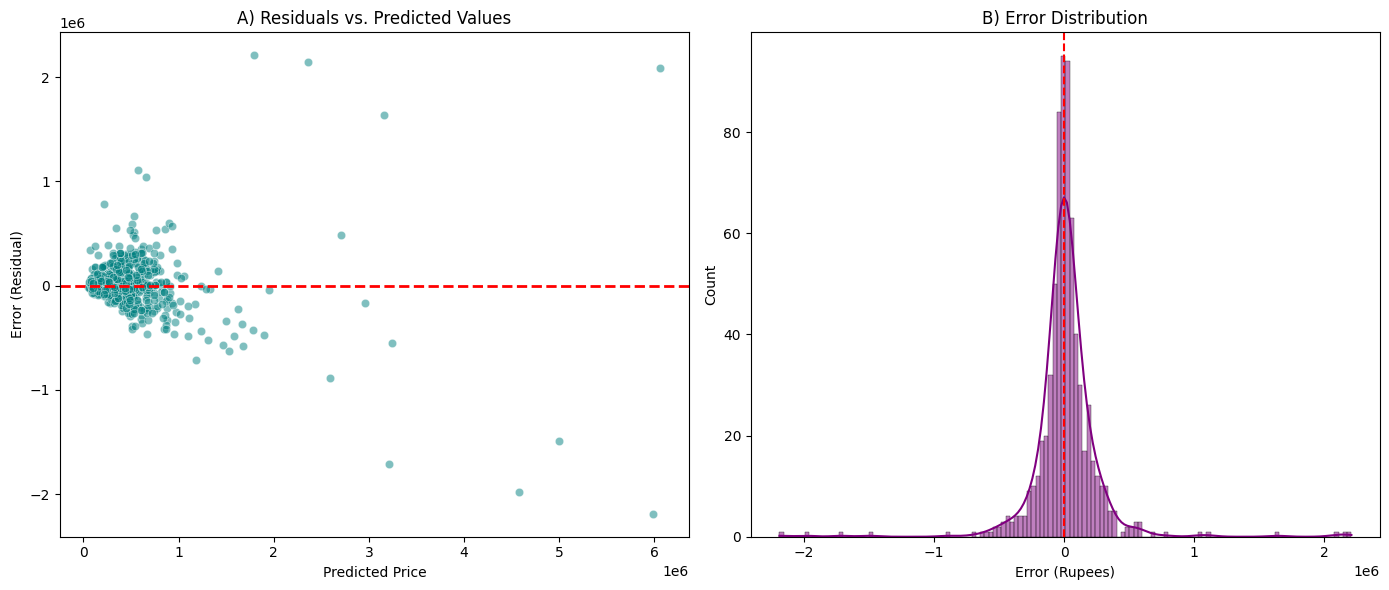

In [ ]:
# I ensure I have predictions in real scale
y_real = np.expm1(y_test)        # Real Price
y_pred = np.expm1(final_model.predict(X_test)) # Prediction

# ------------------------------------------------------------------------------
# 1. EVALUATION (Metrics)
# ------------------------------------------------------------------------------
mse = mean_squared_error(y_real, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_real, y_pred)

print("\n  REPORT ")
print(f"   -> MSE (Mean Squared Error): {mse:,.0f}")
print(f"   -> RMSE (Root Mean Squared Error): ₹ {rmse:,.0f}")
print(f"   -> R2 Score (Explained Variance): {r2:.4f}")

# ------------------------------------------------------------------------------
# 2. INTERPRETATION
# ------------------------------------------------------------------------------
print("\n 2. MODEL INTERPRETATION (What matters most?):")

# I extract the importance of each column
importancia = final_model.feature_importances_
nombres_col = X_train.columns

# I create a DataFrame to sort them
df_imp = pd.DataFrame({'Feature': nombres_col, 'Importance': importancia})
df_imp = df_imp.sort_values(by='Importance', ascending=False).head(10)

# Bar Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_imp, palette='magma')
plt.title('Top 10 Factors defining Car Price')
plt.xlabel('Importance Weight (0 to 1)')
plt.ylabel('Feature')
plt.grid(True, alpha=0.3)
plt.show()


# ------------------------------------------------------------------------------
# 3. VALIDATION
# ------------------------------------------------------------------------------
# I calculate the "Residuals" (The difference between Reality and Prediction)
residuos = y_real - y_pred

print("\n 3. CHECKING ERRORS (Residuals):")
plt.figure(figsize=(14, 6))

# Graph A: Residuals vs Prediction (Homocedasticity)

plt.subplot(1, 2, 1)
sns.scatterplot(x=y_pred, y=residuos, alpha=0.5, color='teal')
plt.axhline(0, color='red', linestyle='--', lw=2)
plt.title('A) Residuals vs. Predicted Values')
plt.xlabel('Predicted Price')
plt.ylabel('Error (Residual)')

# Graph B: Residuals Histogram (Normality)

plt.subplot(1, 2, 2)
sns.histplot(residuos, kde=True, color='purple')
plt.title('B) Error Distribution')
plt.xlabel('Error (Rupees)')
plt.axvline(0, color='red', linestyle='--')

plt.tight_layout()
plt.show()

